# Unidad II · Notebook 1: Comprensión y exploración de los datos

**Proyecto:** Análisis del rendimiento académico de estudiantes
**Dataset:** Student Performance (UCI) · archivo `student-por.csv`
**Alumna:** Brisa Adriana Mendoza Vigueras · 10IDGS-G1

Este notebook corresponde a la fase 2 de CRISP-DM (**comprensión de los datos**). Objetivos:

1. Cargar el dataset original sin modificarlo.
2. Revisar estructura, tipos de datos y calidad (nulos, duplicados, atípicos).
3. Describir las variables con estadística descriptiva.
4. Analizar la variable objetivo `G3` y su relación con las demás variables.
5. Registrar los hallazgos que guiarán la limpieza (Notebook 2).

## 1. Importar bibliotecas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

RAW = Path("../data/raw/student-por.csv")
FIG = Path("../docs/figuras")
FIG.mkdir(parents=True, exist_ok=True)

## 2. Cargar los datos

El archivo usa **punto y coma** (`;`) como separador, por eso se indica `sep=";"`.
Solo se **lee**; el archivo de `data/raw` nunca se modifica.

In [2]:
df = pd.read_csv(RAW, sep=";")
df.shape

(649, 33)

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


**Resultado:** 649 registros (alumnos) y 33 columnas (30 características + `G1`, `G2`, `G3`).

## 3. Estructura y tipos de datos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [5]:
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(exclude="number").columns.tolist()
len(numericas), len(categoricas)

(16, 17)

- **16 numéricas:** varias son escalas ordinales (1 a 5) aunque estén guardadas como número (`famrel`, `Dalc`, `studytime`...).
- **17 categóricas:** 13 binarias (`yes/no`, `GP/MS`, `F/M`...) y 4 nominales (`Mjob`, `Fjob`, `reason`, `guardian`).

## 4. Diccionario de datos

Tabla con el nombre, tipo, descripción y valores de cada variable.

In [6]:
descripciones = {
    "school": "Escuela (GP Gabriel Pereira / MS Mousinho da Silveira)",
    "sex": "Sexo (F / M)",
    "age": "Edad del estudiante",
    "address": "Domicilio (U urbano / R rural)",
    "famsize": "Tamaño de la familia (LE3 <=3 / GT3 >3)",
    "Pstatus": "Padres (T juntos / A separados)",
    "Medu": "Escolaridad de la madre (0 ninguna a 4 superior)",
    "Fedu": "Escolaridad del padre (0 ninguna a 4 superior)",
    "Mjob": "Trabajo de la madre",
    "Fjob": "Trabajo del padre",
    "reason": "Motivo de elección de la escuela",
    "guardian": "Tutor del estudiante",
    "traveltime": "Tiempo de traslado (1 <15 min a 4 >1 h)",
    "studytime": "Horas de estudio semanales (1 <2 h a 4 >10 h)",
    "failures": "Materias reprobadas anteriormente (0 a 3)",
    "schoolsup": "Apoyo educativo extra de la escuela",
    "famsup": "Apoyo educativo de la familia",
    "paid": "Clases extra pagadas",
    "activities": "Actividades extracurriculares",
    "nursery": "Asistió a guardería",
    "higher": "Quiere estudios superiores",
    "internet": "Internet en casa",
    "romantic": "Relación de pareja",
    "famrel": "Calidad de relación familiar (1 a 5)",
    "freetime": "Tiempo libre (1 a 5)",
    "goout": "Salidas con amigos (1 a 5)",
    "Dalc": "Consumo de alcohol entre semana (1 a 5)",
    "Walc": "Consumo de alcohol en fin de semana (1 a 5)",
    "health": "Estado de salud (1 a 5)",
    "absences": "Número de faltas",
    "G1": "Calificación periodo 1 (0 a 20)",
    "G2": "Calificación periodo 2 (0 a 20)",
    "G3": "Calificación final (0 a 20) - VARIABLE OBJETIVO",
}


def tipo(col):
    if df[col].dtype == "object":
        return "Categórica binaria" if df[col].nunique() == 2 else "Categórica nominal"
    return "Numérica ordinal" if df[col].nunique() <= 5 and col not in ("failures",) else "Numérica"


diccionario = pd.DataFrame({
    "variable": df.columns,
    "tipo": [tipo(c) for c in df.columns],
    "descripcion": [descripciones[c] for c in df.columns],
    "valores": [", ".join(map(str, sorted(df[c].unique()))) if df[c].nunique() <= 5
                else f"{df[c].min()} a {df[c].max()}" for c in df.columns],
    "nulos": df.isna().sum().values,
})
diccionario.to_csv("../docs/diccionario_de_datos.csv", index=False, encoding="utf-8-sig")
diccionario

,variable,tipo,descripcion,valores,nulos
0,school,Numérica ordinal,Escuela (GP Gabriel Pereira / MS Mousinho da S...,"GP, MS",0
1,sex,Numérica ordinal,Sexo (F / M),"F, M",0
2,age,Numérica,Edad del estudiante,15 a 22,0
3,address,Numérica ordinal,Domicilio (U urbano / R rural),"R, U",0
4,famsize,Numérica ordinal,Tamaño de la familia (LE3 <=3 / GT3 >3),"GT3, LE3",0
5,Pstatus,Numérica ordinal,Padres (T juntos / A separados),"A, T",0
6,Medu,Numérica ordinal,Escolaridad de la madre (0 ninguna a 4 superior),"0, 1, 2, 3, 4",0
7,Fedu,Numérica ordinal,Escolaridad del padre (0 ninguna a 4 superior),"0, 1, 2, 3, 4",0
8,Mjob,Numérica ordinal,Trabajo de la madre,"at_home, health, other, services, teacher",0
9,Fjob,Numérica ordinal,Trabajo del padre,"at_home, health, other, services, teacher",0


## 5. Calidad de los datos: nulos, duplicados y valores fuera de rango

In [7]:
calidad = pd.Series({
    "valores nulos": df.isna().sum().sum(),
    "registros duplicados": df.duplicated().sum(),
    "G3 fuera de 0-20": (~df["G3"].between(0, 20)).sum(),
    "edad fuera de 15-22": (~df["age"].between(15, 22)).sum(),
    "registros con G3 = 0": (df["G3"] == 0).sum(),
})
calidad

valores nulos            0
registros duplicados     0
G3 fuera de 0-20         0
edad fuera de 15-22      0
registros con G3 = 0    15
dtype: int64

No hay nulos, duplicados ni valores fuera de rango. El único caso especial son los **15 alumnos con G3 = 0**.
Revisemos cómo son:

In [8]:
df.loc[df["G3"] == 0, ["G1", "G2", "G3", "absences", "failures"]]

,G1,G2,G3,absences,failures
163,11,9,0,0,2
440,7,0,0,0,0
519,8,7,0,0,0
563,7,0,0,0,1
567,4,0,0,0,1
583,8,6,0,0,1
586,8,8,0,0,0
597,9,0,0,0,1
603,5,0,0,0,0
605,5,0,0,0,1


**Hallazgo clave:** los 15 alumnos con `G3 = 0` tienen **0 faltas** y varios tienen también `G2 = 0`,
aunque en `G1` sí tenían calificación (4 a 11). En la escala portuguesa un 0 no es una calificación normal:
lo más probable es que **no presentaron la evaluación final (abandono)**.

**Decisión para la limpieza:** se conservan en el Data Mart marcados como `abandono = 1`,
pero se **excluyen del dataset de modelado**, porque su G3 no refleja desempeño real y distorsionaría la regresión.

## 6. Estadística descriptiva de las variables numéricas

In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


## 7. Variable objetivo: G3 (calificación final)

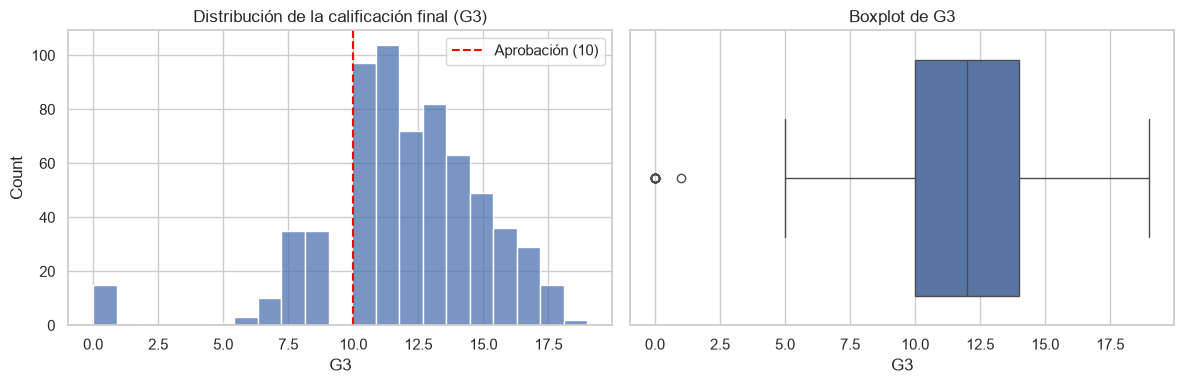

count    649.00
mean      11.91
std        3.23
min        0.00
25%       10.00
50%       12.00
75%       14.00
max       19.00
Name: G3, dtype: float64

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["G3"], bins=21, ax=ax[0], color="#4C72B0")
ax[0].axvline(10, color="red", linestyle="--", label="Aprobación (10)")
ax[0].set_title("Distribución de la calificación final (G3)")
ax[0].legend()
sns.boxplot(x=df["G3"], ax=ax[1], color="#4C72B0")
ax[1].set_title("Boxplot de G3")
plt.tight_layout()
plt.savefig(FIG / "01_distribucion_G3.png", dpi=120)
plt.show()

df["G3"].describe().round(2)

- La media es **11.9** y la mediana **12**: la mayoría aprueba.
- Se ve un grupo aislado en 0 (los abandonos).

### Variable de clasificación derivada de G3
Criterio documentado en la Unidad I: **aprobado si G3 ≥ 10** (escala portuguesa).
Alternativa de 3 niveles: Bajo 0-9, Medio 10-13, Alto 14-20.

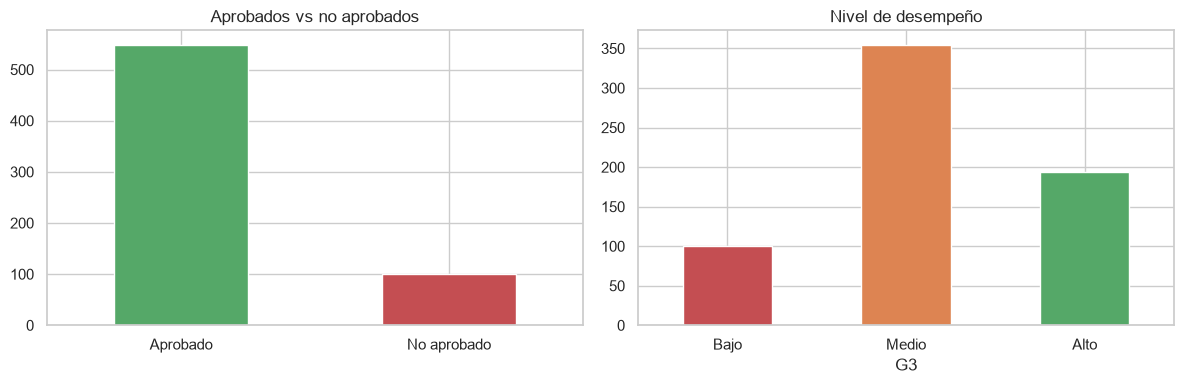

Aprobado       0.846
No aprobado    0.154
Name: proportion, dtype: float64

In [11]:
aprobado = np.where(df["G3"] >= 10, "Aprobado", "No aprobado")
nivel = pd.cut(df["G3"], bins=[-1, 9, 13, 20], labels=["Bajo", "Medio", "Alto"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(aprobado).value_counts().plot.bar(ax=ax[0], color=["#55A868", "#C44E52"], rot=0)
ax[0].set_title("Aprobados vs no aprobados")
nivel.value_counts().reindex(["Bajo", "Medio", "Alto"]).plot.bar(
    ax=ax[1], color=["#C44E52", "#DD8452", "#55A868"], rot=0)
ax[1].set_title("Nivel de desempeño")
plt.tight_layout()
plt.savefig(FIG / "02_clases.png", dpi=120)
plt.show()

pd.Series(aprobado).value_counts(normalize=True).round(3)

**Clases desbalanceadas:** 84.6 % aprobados vs 15.4 % no aprobados. En la Unidad III habrá que usar
división estratificada y `class_weight="balanced"`, y fijarse en el *recall* de "No aprobado".

## 8. Distribución de las variables numéricas

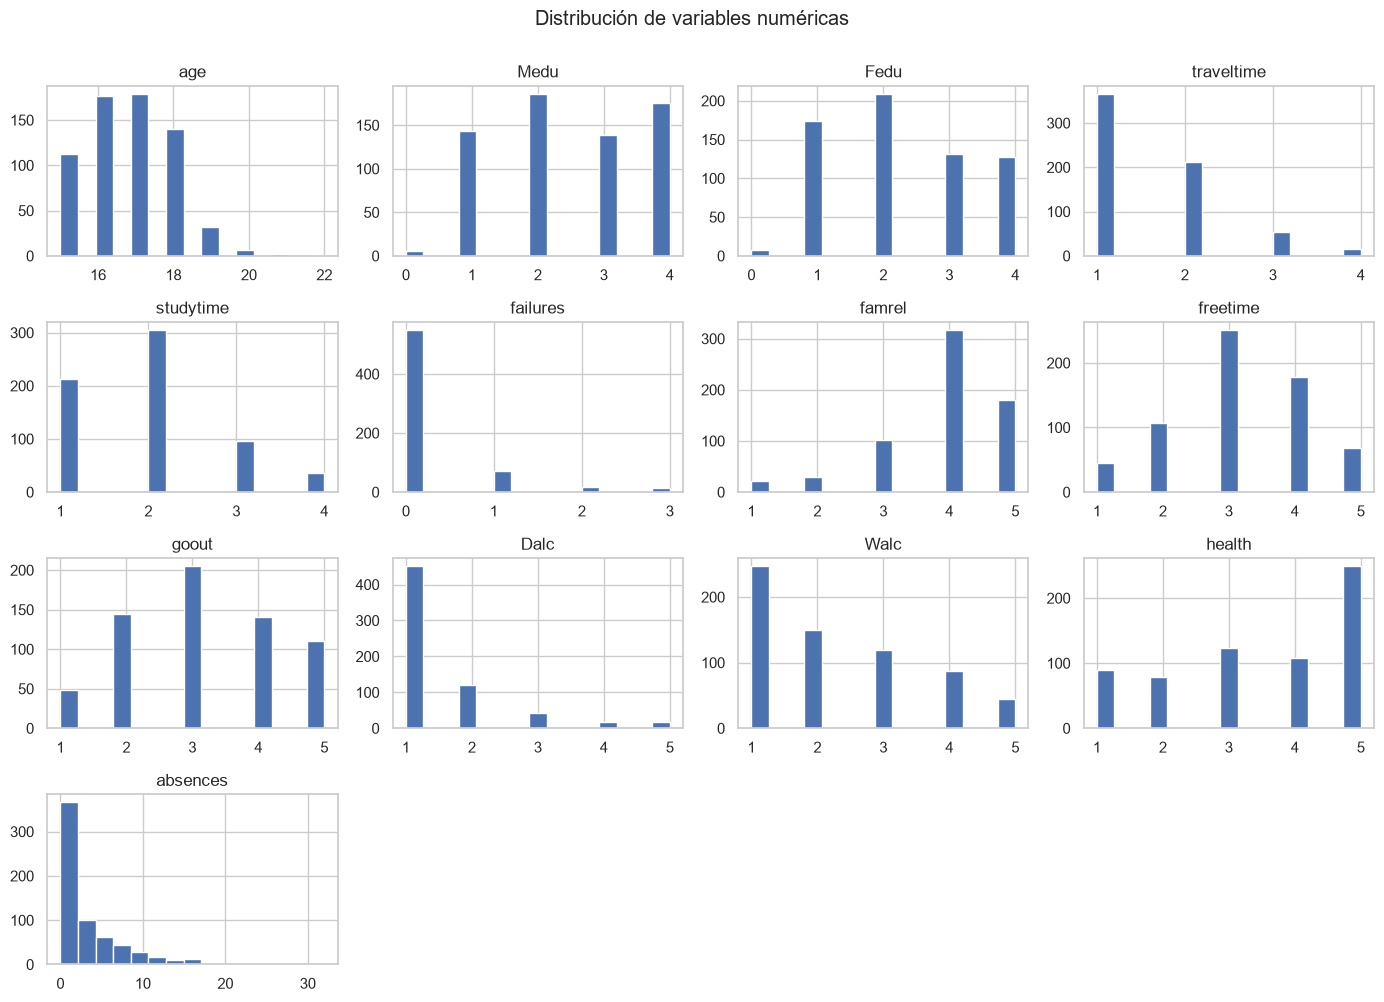

In [12]:
cols = [c for c in numericas if c not in ("G1", "G2", "G3")]
df[cols].hist(bins=15, figsize=(14, 10), color="#4C72B0")
plt.suptitle("Distribución de variables numéricas", y=1.0)
plt.tight_layout()
plt.savefig(FIG / "03_histogramas.png", dpi=120)
plt.show()

Observaciones:
- `failures`: la gran mayoría tiene 0 reprobadas.
- `Dalc` y `Walc`: concentrados en 1 (consumo muy bajo).
- `absences`: muy sesgada a la derecha (pocos alumnos con muchas faltas).

## 9. Valores atípicos (outliers) en faltas

Se usa el criterio del **rango intercuartílico (IQR)**: es atípico lo que está por encima de Q3 + 1.5·IQR.

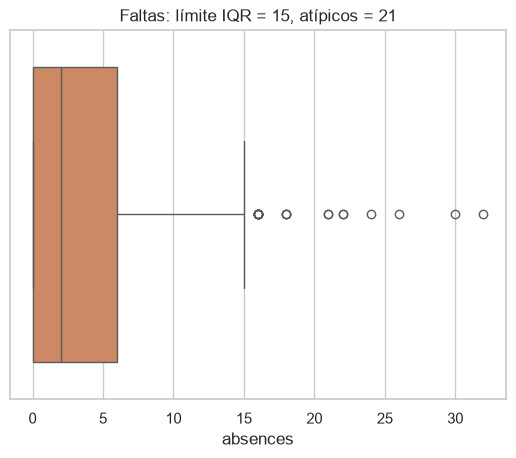

In [13]:
q1, q3 = df["absences"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = (df["absences"] > limite).sum()

sns.boxplot(x=df["absences"], color="#DD8452")
plt.title(f"Faltas: límite IQR = {limite:.0f}, atípicos = {atipicos}")
plt.savefig(FIG / "04_outliers_faltas.png", dpi=120)
plt.show()

Hay 21 alumnos con más de 15 faltas. Son valores **posibles** (no errores), así que no se eliminan;
para el modelado se **recortan** a 15 (*capping*) para que no dominen a los modelos.

## 10. Variables categóricas

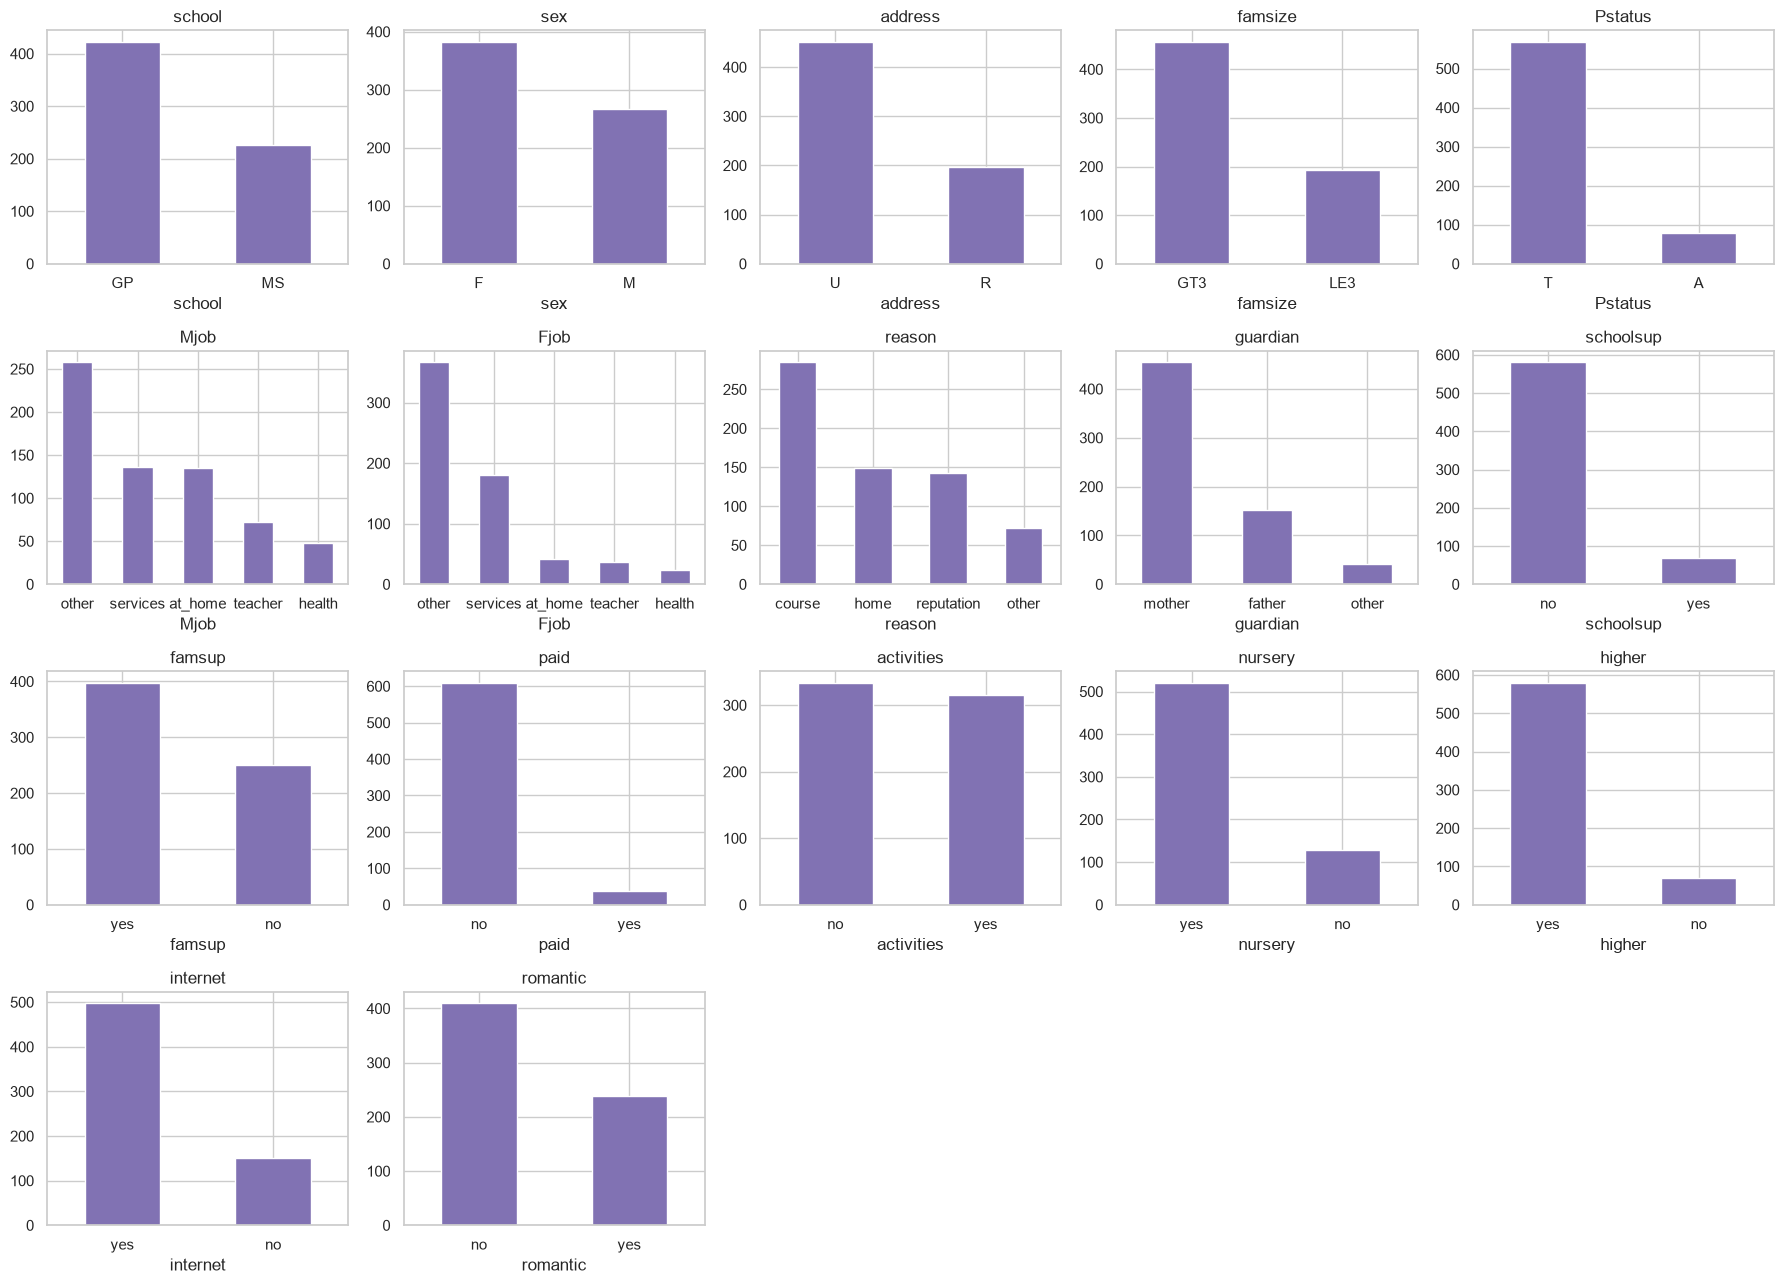

In [14]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for ax, col in zip(axes.flat, categoricas):
    df[col].value_counts().plot.bar(ax=ax, color="#8172B3", rot=0)
    ax.set_title(col)
for ax in axes.flat[len(categoricas):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "05_categoricas.png", dpi=120)
plt.show()

## 11. Correlación entre variables numéricas

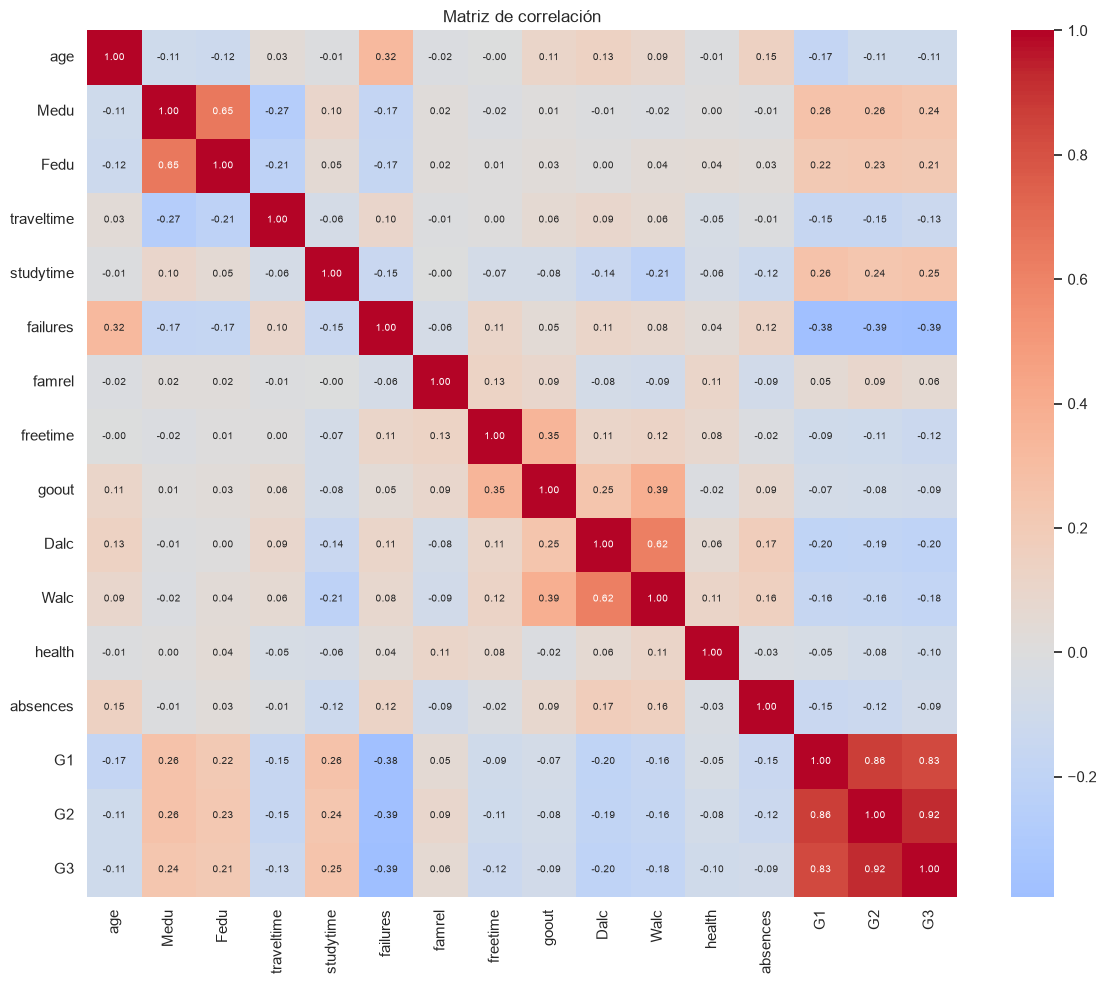

In [15]:
corr = df[numericas].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.tight_layout()
plt.savefig(FIG / "06_correlacion.png", dpi=120)
plt.show()

In [16]:
corr["G3"].drop("G3").sort_values()

failures     -0.393316
Dalc         -0.204719
Walc         -0.176619
traveltime   -0.127173
freetime     -0.122705
age          -0.106505
health       -0.098851
absences     -0.091379
goout        -0.087641
famrel        0.063361
Fedu          0.211800
Medu          0.240151
studytime     0.249789
G1            0.826387
G2            0.918548
Name: G3, dtype: float64

**Interpretación de la correlación con G3:**

| Variable | Correlación | Lectura |
|---|---|---|
| `G2`, `G1` | 0.92 / 0.83 | Muy alta: las parciales casi determinan la final (riesgo de fuga de información) |
| `failures` | -0.39 | La más fuerte fuera de las calificaciones: más reprobadas previas → menor G3 |
| `studytime` | 0.25 | Más horas de estudio → mayor G3 |
| `Medu`, `Fedu` | 0.24 / 0.21 | Mayor escolaridad de los padres → mayor G3 |
| `Dalc`, `Walc` | -0.20 / -0.18 | Más consumo de alcohol → menor G3 |

Recordatorio: **correlación no implica causalidad**.

## 12. G3 según variables categóricas importantes

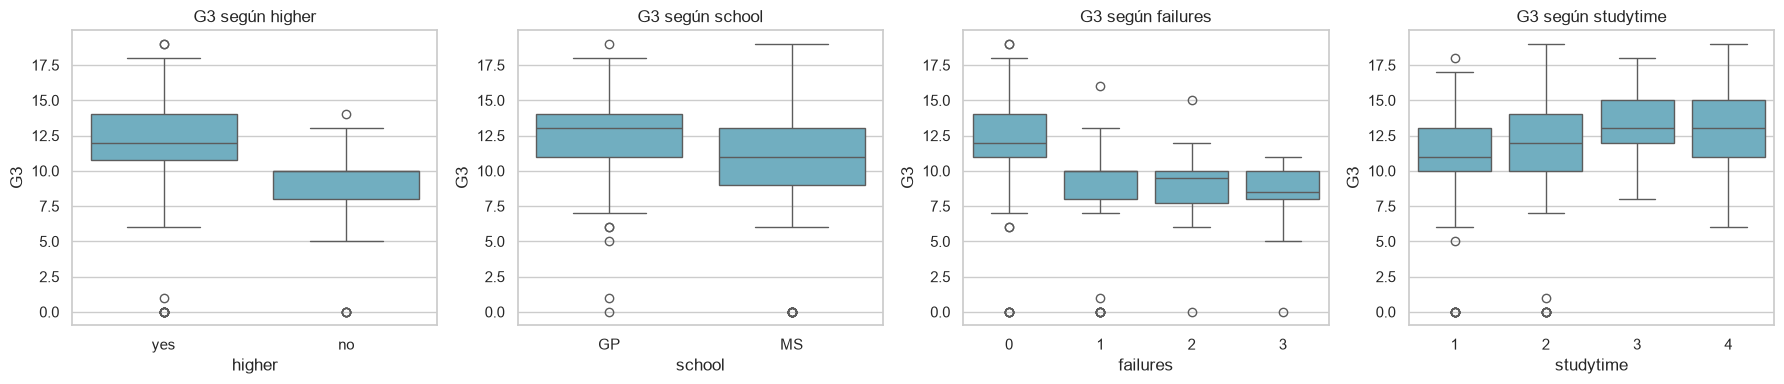

,count,mean
higher,,
no,69,8.80
yes,580,12.28


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["higher", "school", "failures", "studytime"]):
    sns.boxplot(data=df, x=col, y="G3", ax=ax, color="#64B5CD")
    ax.set_title(f"G3 según {col}")
plt.tight_layout()
plt.savefig(FIG / "07_G3_por_categoria.png", dpi=120)
plt.show()

df.groupby("higher")["G3"].agg(["count", "mean"]).round(2)

- Quienes **quieren estudios superiores** (`higher = yes`) tienen un promedio ~3 puntos mayor.
- La escuela **GP** tiene mejor promedio que **MS**.
- A más `failures`, menor calificación; a más `studytime`, mayor.

## 13. Conclusiones de la exploración

1. **Calidad:** el dataset está completo (0 nulos, 0 duplicados, sin valores fuera de rango).
2. **G3 = 0:** 15 registros de probable abandono → se marcan y se excluyen del modelado.
3. **Faltas:** 21 atípicos válidos → se recortan a 15 para el modelado.
4. **Codificación necesaria:** 13 variables binarias → 0/1 y 4 nominales → one-hot.
5. **Desbalance de clases:** 84.6 % / 15.4 % → considerar en la Unidad III.
6. **Variables más relacionadas con G3:** `G2`, `G1`, `failures`, `studytime`, `Medu`, `higher`, `Dalc`.

Siguiente paso: **Notebook 2 – Limpieza, transformación y ETL**.